# 01 — Exploratory Data Analysis: Employee Attrition

**Goal:** understand which employee characteristics are associated with attrition before building the model.

**Dataset:** IBM HR Analytics Employee Attrition & Performance (1,470 employees, 35 columns). The target is `Attrition` (Yes/No).

**Outline**
1. Data overview & quality checks
2. Target distribution
3. Attrition by categorical factors
4. Attrition by age, income and tenure
5. Correlations
6. Key findings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

# utf-8-sig strips the BOM at the start of the file
df = pd.read_csv("../data/dataset.csv", encoding="utf-8-sig")
df["Left"] = df["Attrition"].eq("Yes")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Left
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,True
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,False
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,True
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,False
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,False


## 1. Data Overview & Quality Checks

In [2]:
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

# Columns with a single value carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Constant columns: {constant_cols}")

Shape: (1470, 36)
Missing values: 0
Duplicate rows: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


The data is clean: no missing values and no duplicates. `EmployeeCount`, `Over18` and `StandardHours` hold a single value, and `EmployeeNumber` is an ID. All four are dropped before modelling (`src/data_processing.py`).

## 2. Target Distribution

Attrition rate: 16.1% (237 of 1470 employees)


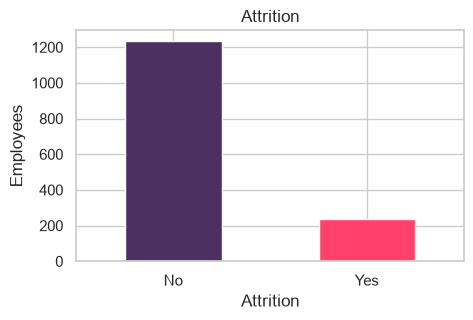

In [3]:
rate = df["Left"].mean()
print(f"Attrition rate: {rate:.1%} ({df['Left'].sum()} of {len(df)} employees)")

ax = df["Attrition"].value_counts().plot.bar(color=["#4B3061", "#ff416c"], rot=0, figsize=(5, 3))
ax.set_title("Attrition")
ax.set_ylabel("Employees")
plt.show()

Only 16.1% of employees left, so the target is **imbalanced**. A model that always predicts "No" already scores ~84% accuracy. That is why the model is evaluated on recall, F1 and PR-AUC instead of accuracy.

## 3. Attrition by Categorical Factors

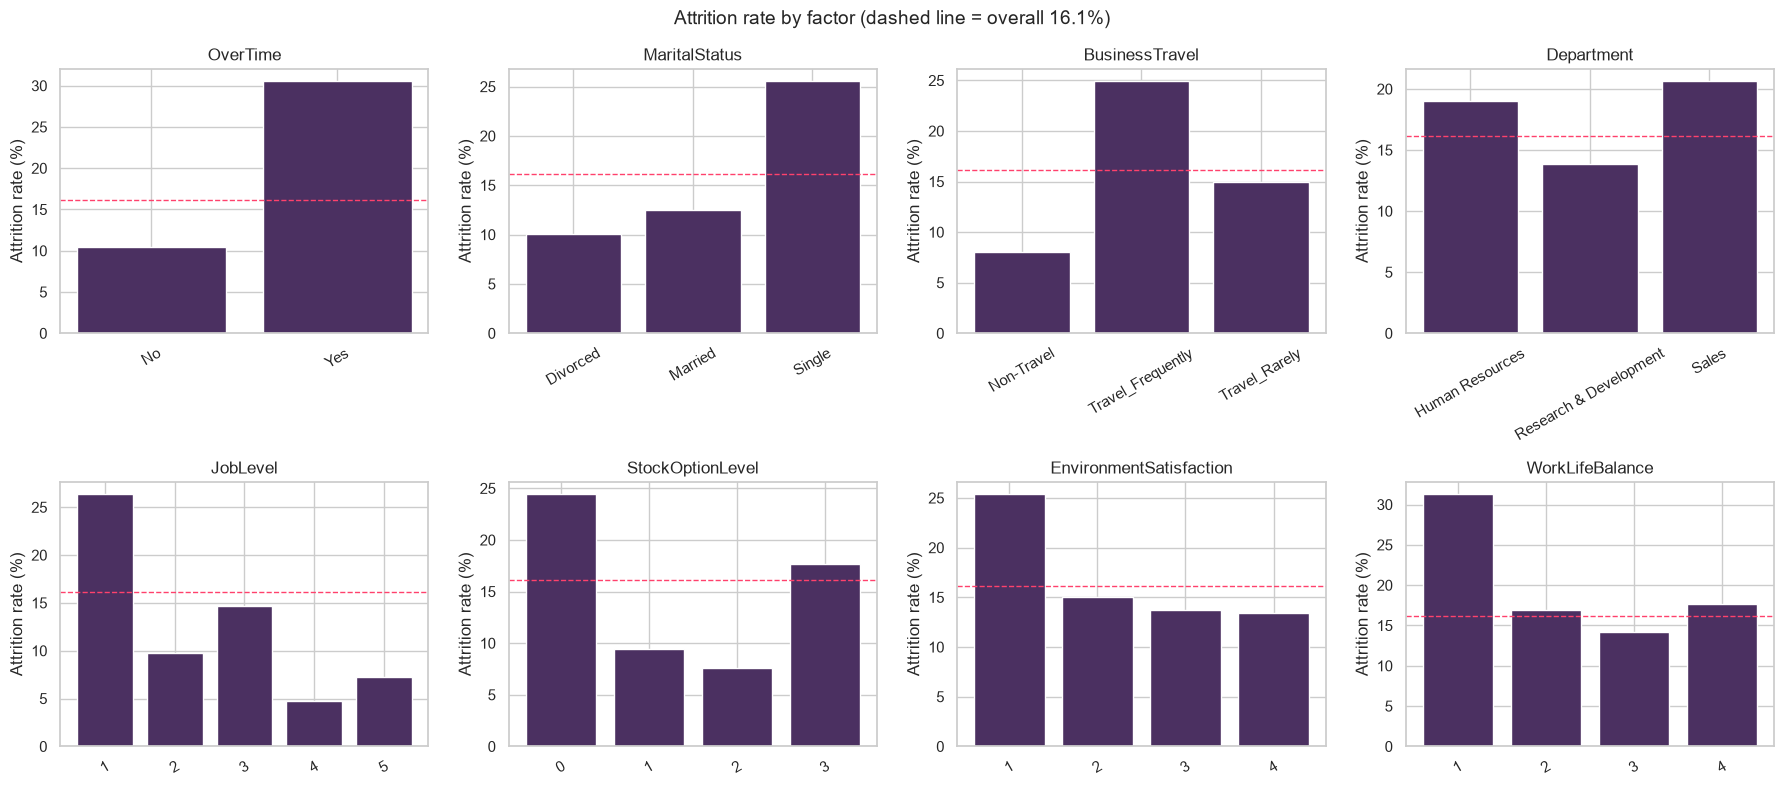

In [4]:
def attrition_rate(col):
    return df.groupby(col)["Left"].agg(rate="mean", employees="size").sort_values("rate", ascending=False)

factors = ["OverTime", "MaritalStatus", "BusinessTravel", "Department",
           "JobLevel", "StockOptionLevel", "EnvironmentSatisfaction", "WorkLifeBalance"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, factors):
    data = attrition_rate(col).sort_index()
    ax.bar(data.index.astype(str), data["rate"] * 100, color="#4B3061")
    ax.axhline(rate * 100, color="#ff416c", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_ylabel("Attrition rate (%)")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Attrition rate by factor (dashed line = overall 16.1%)", fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
attrition_rate("JobRole").style.format({"rate": "{:.1%}"})

,rate,employees
JobRole,,
Sales Representative,39.8%,83
Laboratory Technician,23.9%,259
Human Resources,23.1%,52
Sales Executive,17.5%,326
Research Scientist,16.1%,292
Manufacturing Director,6.9%,145
Healthcare Representative,6.9%,131
Manager,4.9%,102
Research Director,2.5%,80


**Observations**
- **Overtime** is the strongest single factor: 30.5% attrition with overtime vs 10.4% without.
- **Single** employees leave at 25.5%, more than double the rate of married (12.5%) or divorced (10.1%) employees.
- **Frequent travellers** leave at 24.9% vs 8.0% for non-travellers.
- **Job level 1** has 26.3% attrition, the highest of all levels.
- **No stock options** (level 0) goes with 24.4% attrition vs 7.6–9.4% at levels 1–2.
- **Low environment satisfaction** (1) and **poor work-life balance** (1) both push attrition above 25%.
- By role, **Sales Representatives** (39.8%) and **Laboratory Technicians** (23.9%) leave most often.

## 4. Attrition by Age, Income and Tenure

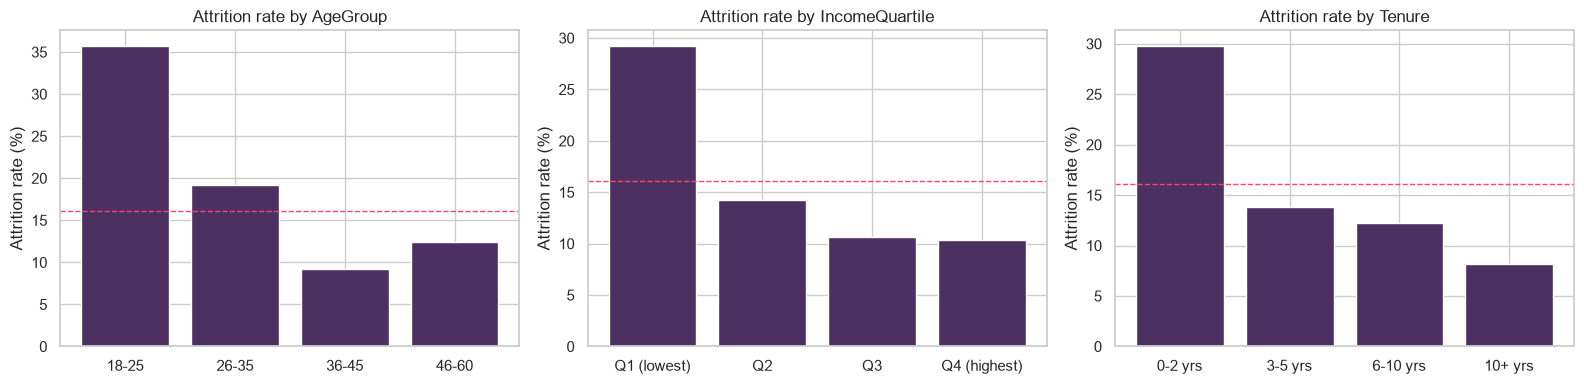

Median monthly income:
Attrition
No     5204.0
Yes    3202.0
Name: MonthlyIncome, dtype: float64


In [6]:
df["AgeGroup"] = pd.cut(df["Age"], [17, 25, 35, 45, 60], labels=["18-25", "26-35", "36-45", "46-60"])
df["IncomeQuartile"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
df["Tenure"] = pd.cut(df["YearsAtCompany"], [-1, 2, 5, 10, 40], labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "10+ yrs"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["AgeGroup", "IncomeQuartile", "Tenure"]):
    data = df.groupby(col, observed=True)["Left"].mean() * 100
    ax.bar(data.index.astype(str), data.values, color="#4B3061")
    ax.axhline(rate * 100, color="#ff416c", linestyle="--", linewidth=1)
    ax.set_title(f"Attrition rate by {col}")
    ax.set_ylabel("Attrition rate (%)")
plt.tight_layout()
plt.show()

print("Median monthly income:")
print(df.groupby("Attrition")["MonthlyIncome"].median())

**Observations**
- Attrition falls steadily with age: **35.8%** for employees aged 18–25 vs 9.2% for 36–45.
- The **lowest income quartile** (median ~\$2,400/month) has 29.3% attrition, roughly triple the top two quartiles (~10%). Leavers earn a median of \$3,202 vs \$5,204 for those who stay.
- **New employees** churn most: 29.8% in the first two years vs 8.1% after ten years.

Age, income, job level and tenure are correlated, so together they describe one profile: **early-career, lower-paid employees**.

## 5. Correlations

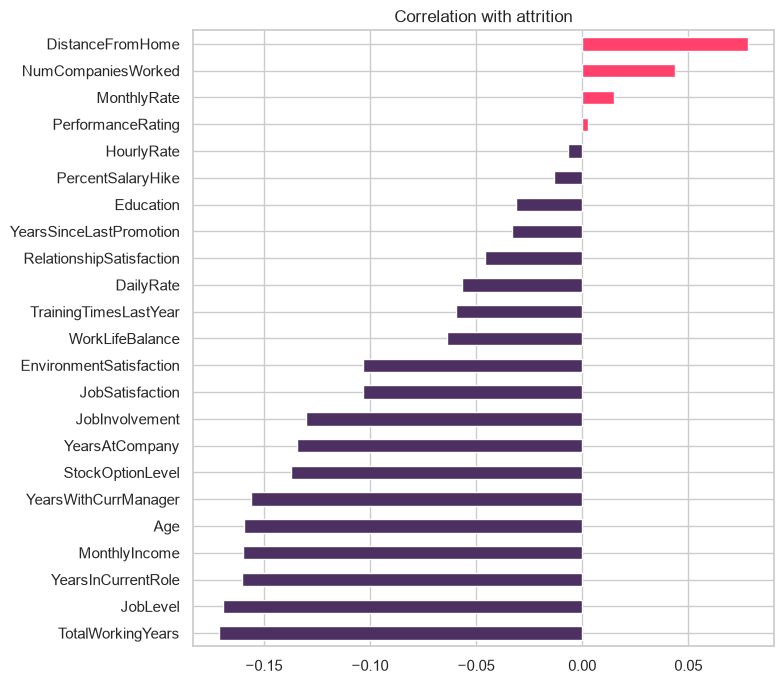

In [7]:
numeric = df.select_dtypes("number").drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"])
numeric["Left"] = df["Left"].astype(int)

corr_with_target = numeric.corr()["Left"].drop("Left").sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
corr_with_target.plot.barh(ax=ax, color=np.where(corr_with_target > 0, "#ff416c", "#4B3061"))
ax.set_title("Correlation with attrition")
plt.tight_layout()
plt.show()

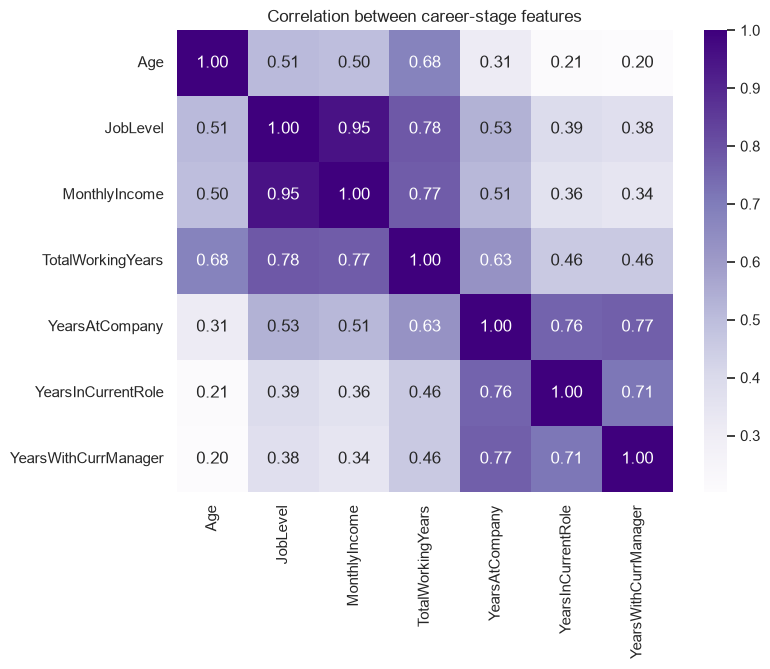

In [8]:
cols = ["Age", "JobLevel", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
        "YearsInCurrentRole", "YearsWithCurrManager"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="Purples")
plt.title("Correlation between career-stage features")
plt.show()

Individual correlations with attrition are weak (all below |0.2|), so no single numeric feature predicts attrition on its own. This motivates a multivariate model.

Career-stage features are strongly correlated with each other (e.g. `JobLevel` vs `MonthlyIncome` ≈ 0.95). Tree models like XGBoost handle this fine, but it means SHAP importance can be spread across related features.

## 6. Key Findings

1. **Attrition is imbalanced (16.1%)**, so accuracy is a misleading metric. The model is tuned on PR-AUC and evaluated on recall and F1.
2. **Overtime nearly triples the attrition rate** (30.5% vs 10.4%). It is also the top feature in the model's SHAP ranking.
3. **Early-career, lower-paid employees are most at risk.** Ages 18–25 (35.8%), job level 1 (26.3%), the lowest income quartile (29.3%) and the first two years at the company (29.8%) all stand out.
4. **Single employees and frequent travellers** leave at about 25%, versus 10–13% for married/divorced employees and 8% for non-travellers.
5. **Stock options matter.** Employees without stock options leave at 24.4% vs 7.6–9.4% with level 1–2 options.

**Implications for HR**
- Review overtime load first: 53.6% of leavers worked overtime, while only 28.3% of all employees do.
- Focus retention on the first two years: onboarding, mentoring and a clear path from job level 1.
- Revisit pay and stock options for entry-level roles, especially Sales Representatives and Laboratory Technicians.